# 10 - Regressão
Vamos aprender sobre como usar técnicas de ajuste de curvas que buscam modelar a relação entre variáveis, como o método dos mínimos quadrados, para estimar os coeficientes da equação.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana10
```

Faça o checkout nessa nova branch:

```bash
git checkout semana10
```

<hr />

## Atividade 1
Escreva o método de regressão por quadrado mínimo dentro do arquivo $utils/algoritmos.py$.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join('..')))

from utils.algoritmos import regressao


def ajustar(x, y, v, nomes, titulo):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    A = regressao(x, y, v)
    for nome, a in zip(nomes, A):
        print(f"{nome} = {a:.8f}")
    xs = np.linspace(x.min() - 0.1, x.max() + 0.1, 400)
    plt.figure(figsize=(7, 4))
    plt.scatter(x, y, color="blue", label="Pontos dados")
    plt.plot(xs, v(xs) @ A, color="red", label="Ajuste")
    plt.title(titulo)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True, linestyle=":")
    plt.legend()
    plt.tight_layout()
    plt.show()
    return A


reta = lambda x: np.column_stack((np.ones(len(x)), x))

Seja dado o conjunto de pontos  
$\{(-0.35, 0.2),\ (0.15, -0.5),\ (0.23, 0.54),\ (0.35, 0.7)\}$.

Encontre a função linear $f(x) = a_1 + a_2x$ que melhor se ajusta aos pontos dados no **sentido dos mínimos quadrados**.  
Em seguida, desenhe um gráfico com os pontos e o esboço da função ajustada.

**Resposta esperada:**

$$
f(x) = -0.47x + 0.19
$$

a1 = 0.18992262
a2 = 0.47449877


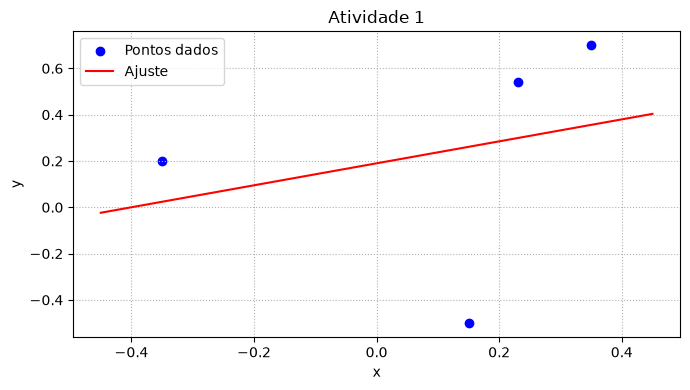

array([0.18992262, 0.47449877])

In [2]:
ajustar([-0.35, 0.15, 0.23, 0.35], [0.2, -0.5, 0.54, 0.7], reta, ["a1", "a2"], "Atividade 1")

## Atividade 2
Seja dado o conjunto de pontos  
$\{(-1.94,\,1.02),\ (-1.44,\,0.59),\ (0.93,\,-0.28),\ (1.39,\,-1.04)\}$.

Encontre a função linear $f(x) = a_1 + a_2x$ que melhor se ajusta aos pontos dados no sentido dos **mínimos quadrados**. Encontre o valor de $f(1)$. Em seguida, desenhe um gráfico com os pontos e o esboço da função ajustada.

**Resposta esperada:**

$$
f(x) = -0.06891127x -0.53362743 
$$

$$
f(1) = -0.6025387
$$

a1 = -0.06891127
a2 = -0.53362743


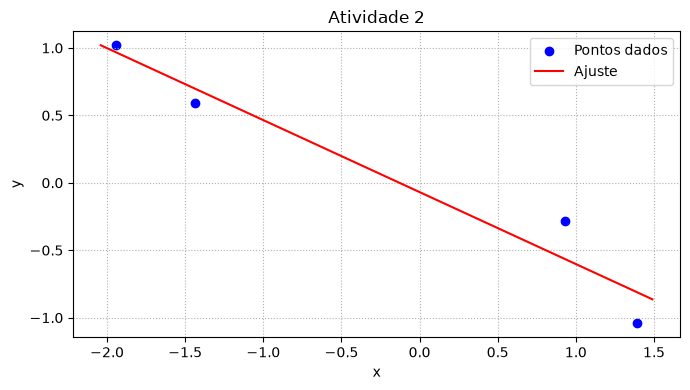

f(1) = -0.6025387


In [3]:
A = ajustar([-1.94, -1.44, 0.93, 1.39], [1.02, 0.59, -0.28, -1.04], reta, ["a1", "a2"], "Atividade 2")
print(f"f(1) = {A[0] + A[1]:.7f}")

## Atividade 3
Encontrar a parábola $y = ax^2 + bx + c$ que melhor aproxima o seguinte conjunto de dados:

| $i$ | 1 | 2 | 3 | 4 | 5 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $x_i$ | 0.01 | 1.02 | 2.04 | 2.95 | 3.55 |
| $y_i$ | 1.99 | 4.55 | 7.20 | 9.51 | 10.82 |

**Resposta esperada:**

$$
y = -0.0407898x^2 + 2.6613293x + 1.9364598
$$

a = -0.04078983
b = 2.66132929
c = 1.93645978


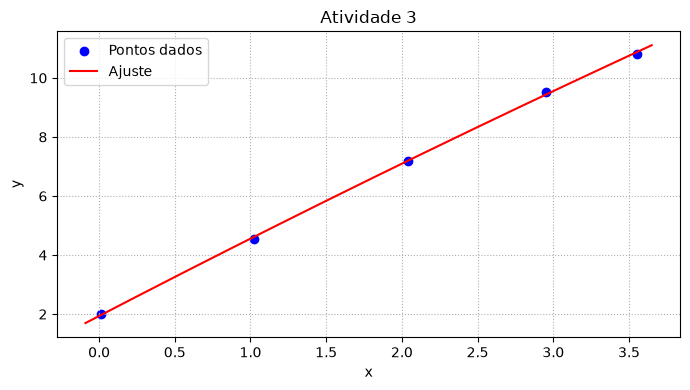

array([-0.04078983,  2.66132929,  1.93645978])

In [4]:
parabola = lambda x: np.column_stack((x**2, x, np.ones(len(x))))

ajustar(
    [0.01, 1.02, 2.04, 2.95, 3.55],
    [1.99, 4.55, 7.20, 9.51, 10.82],
    parabola,
    ["a", "b", "c"],
    "Atividade 3",
)

## Atividade 4
Dado o seguinte conjunto de dados:

| $x_i$ | 0.0 | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $y_i$ | 31 | 35 | 37 | 33 | 28 | 20 | 16 | 15 | 18 | 23 | 31 |

**a)** Encontre a função do tipo  
$f(x) = a + b \sin(2\pi x) + c \cos(2\pi x)$  
que melhor aproxima os valores dados.

**b)** Encontre a função do tipo  
$f(x) = a + bx + cx^2 + dx^3$  
que melhor aproxima os valores dados.

**Respostas esperadas:**

$$
\text{a)}\quad a = 25.638625,\quad b = 9.8591874,\quad c = 4.9751219
$$

$$
\text{b)}\quad a = 31.475524,\quad b = 65.691531,\quad c = -272.84382,\quad d = 208.23621
$$

a = 25.63862528
b = 9.85918743
c = 4.97512193


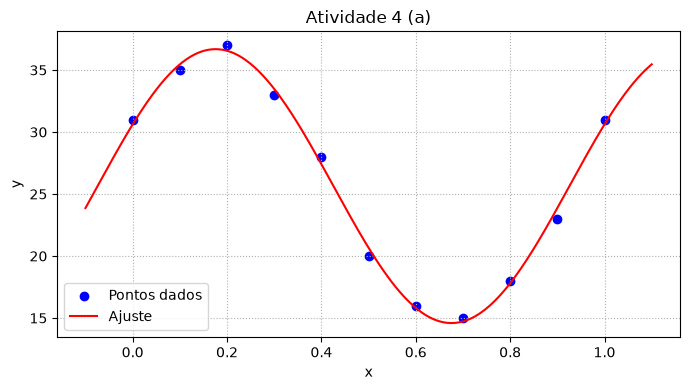

a = 31.47552448
b = 65.69153069
c = -272.84382284
d = 208.23620824


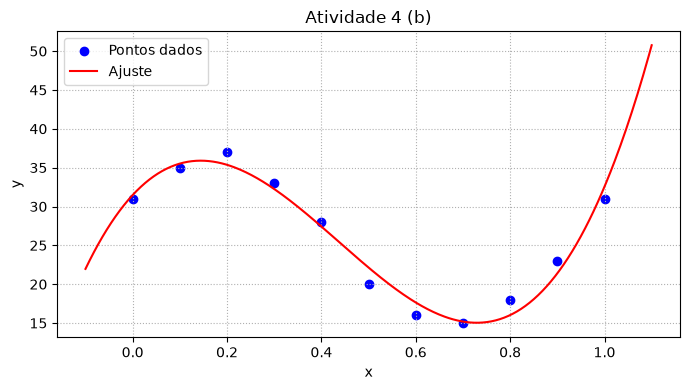

array([  31.47552448,   65.69153069, -272.84382284,  208.23620824])

In [5]:
x = np.round(np.arange(0, 1.01, 0.1), 1)
y = [31, 35, 37, 33, 28, 20, 16, 15, 18, 23, 31]

senocosseno = lambda x: np.column_stack((np.ones(len(x)), np.sin(2 * np.pi * x), np.cos(2 * np.pi * x)))
cubica = lambda x: np.column_stack((np.ones(len(x)), x, x**2, x**3))

ajustar(x, y, senocosseno, ["a", "b", "c"], "Atividade 4 (a)")
ajustar(x, y, cubica, ["a", "b", "c", "d"], "Atividade 4 (b)")

## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 10"
git push origin semana10
```